# Ćwiczenie O10 — Cairns
## Badanie widm emisyjnych za pomocą spektroskopu pryzmatycznego

Kalibracja skali spektroskopu (krzywa dyspersji) na liniach He, Hg i Cd, test kalibracji na lampie cynkowej (Zn).
Wykresy surowe (`*_raw.pdf`) idą do sekcji *Wyniki pomiarów*, wykresy z dopasowaniem (`*.pdf`) do *Opracowania wyników*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

import locale

plt.rcParams.update({'figure.dpi': 150, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3})

# przecinek dziesiętny na osiach wykresów (jak w sprawozdaniu)
locale.setlocale(locale.LC_NUMERIC, 'pl_PL.UTF-8')
plt.rcParams['axes.formatter.use_locale'] = True

def pl(x, spec):
    '''Liczba sformatowana z przecinkiem dziesiętnym — do legend i opisów na wykresach.'''
    return format(x, spec).replace('.', ',')

### Wczytanie danych

`spectral_lines.csv` — położenia linii $x$ na skali umownej spektroskopu [dz.], niepewność odczytu
$u_x = 0{,}2$ dz. (paralaksa, szerokość obrazu szczeliny, ocena środka linii okiem), barwa i jasność w skali 1–10.

`reference_lines.csv` — tablicowe długości fal w powietrzu [nm] z NIST ASD przypisane liniom źródeł
kalibracyjnych (He, Hg, Cd) i testowego (Zn). Żółty dublet rtęci 576,96 / 579,07 nm nie był rozdzielony —
przyjęto średnią z niepewnością równą połowie odstępu składowych, $u_\lambda = 1{,}05$ nm.

In [2]:
lines = pd.read_csv('spectral_lines.csv')
ref = pd.read_csv('reference_lines.csv')
d = lines.merge(ref, on=['symbol', 'line'], how='left')
d['role'] = d['role'].fillna('')
print(d.groupby('element', sort=False).size().to_string())

element
Neon    24
Hel     10
Rtęć     4
Sód     14
Cynk     8
Kadm    10


### Odrzucone linie

- linie o jasności 1 („bardzo słabe”) — obraz na granicy widoczności, środek linii nie dał się pewnie wskazać;
- linie Na 13 i 14 — leżą poza podziałką skali, ich położenie było tylko szacowane.

Pozostałe linie źródeł kalibracyjnych, których nie przypisano (Cd 2 i Cd 4), są słabe i nie mają
jednoznacznego odpowiednika w tablicach — nie wchodzą do kalibracji, ale nie są odrzucane jako błędne odczyty.

In [3]:
d['rejected'] = ''
d.loc[d['intensity'] == 1, 'rejected'] = 'bardzo słaba (jasność 1)'
d.loc[(d['symbol'] == 'Na') & d['line'].isin([13, 14]), 'rejected'] = 'poza skalą (szacunkowo)'
print(d.loc[d['rejected'] != '', ['symbol', 'line', 'color', 'x', 'intensity', 'rejected']].to_string(index=False))

symbol  line                                       color    x  intensity                 rejected
    Ne    22                 szarozielony (bardzo słaby) 11.5          1 bardzo słaba (jasność 1)
    Ne    23             szaroniebieskawy (bardzo słaby) 12.0          1 bardzo słaba (jasność 1)
    Hg     3              błękitnozielony (bardzo słaby) 13.0          1 bardzo słaba (jasność 1)
    Na     9           fioletowoniebieski (bardzo słaby) 16.8          1 bardzo słaba (jasność 1)
    Na    13 niebieskofioletowy (poza skalą, szacunkowo) 21.1          5  poza skalą (szacunkowo)
    Na    14          fioletowy (poza skalą, szacunkowo) 21.8          4  poza skalą (szacunkowo)
    Zn     2                     różowawy (bardzo słaby)  7.2          1 bardzo słaba (jasność 1)
    Cd     3                morskozielony (bardzo słaby)  8.5          1 bardzo słaba (jasność 1)
    Cd     8                morskozielony (bardzo słaby) 17.0          1 bardzo słaba (jasność 1)
    Cd    10        

### Wyniki pomiarów — obserwowane widma

Każda linia jako pionowa kreska na skali umownej, wysokość proporcjonalna do ocenionej jasności,
kolor odpowiada zanotowanej barwie. Wszystkie linie, bez podziału na odrzucone.

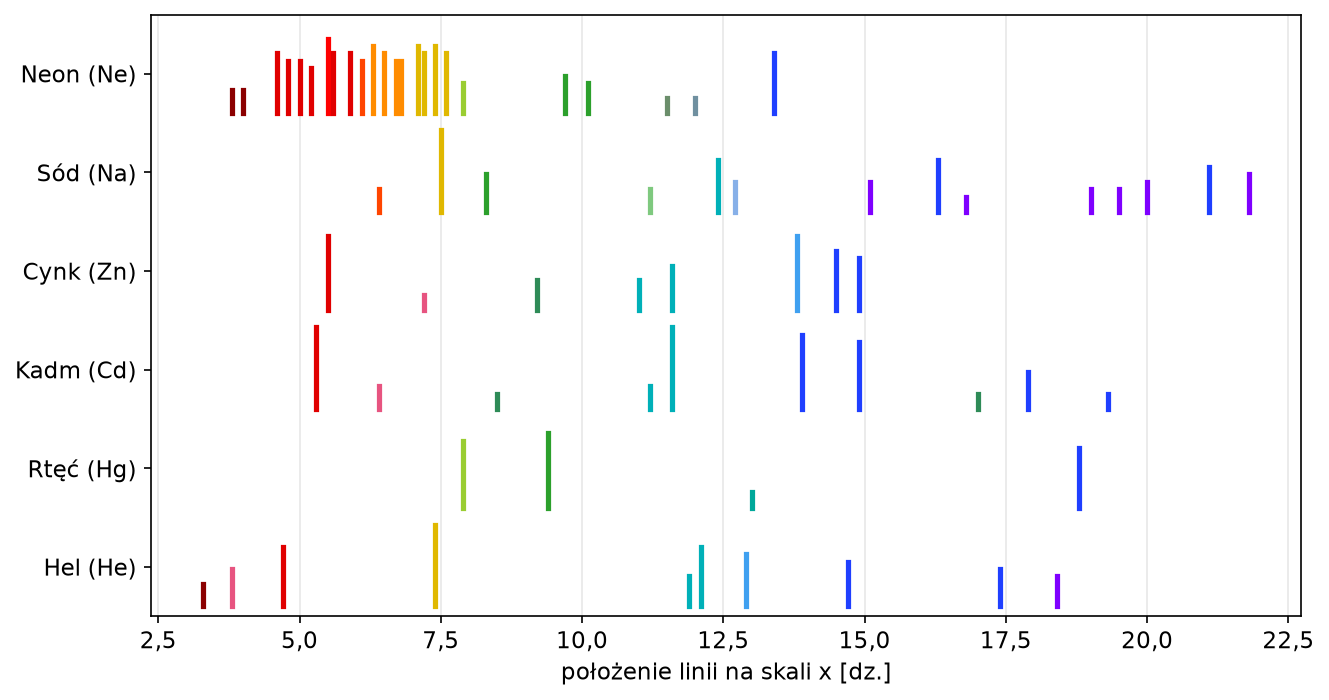

In [4]:
# barwa z notatek -> kolor na wykresie (decyduje słowo, które pojawia się najwcześniej w opisie)
COLOR_WORDS = {
    'fiolet': '#7f00ff', 'indygo': '#4b0082', 'cyjan': '#00b0b8', 'zielononiebiesk': '#00b0b8',
    'błękitnoziel': '#00a89a', 'błękit': '#3fa0f0', 'niebiesk': '#1f3fff', 'morsk': '#2e8b57',
    'żółtoziel': '#9acd32', 'ziel': '#2ca02c', 'szaroziel': '#6b8e6b', 'szaroniebiesk': '#7090a0',
    'czerwono-pomar': '#ff4500', 'pomarańczowoczerw': '#ff4500', 'pomarańcz': '#ff8c00',
    'żółt': '#e0b800', 'różow': '#e75480', 'purpur': '#8b0040', 'ciemnoczerw': '#8b0000',
    'jaskrawoczerw': '#ff0000', 'czerw': '#e00000', 'bladoziel': '#7fc97f', 'bladoniebiesk': '#87b0e8',
}

def line_color(name):
    name = name.lower()
    hits = [(name.find(k), -len(k), c) for k, c in COLOR_WORDS.items() if k in name]
    return min(hits)[2] if hits else 'gray'

ORDER = ['He', 'Hg', 'Cd', 'Zn', 'Na', 'Ne']

def plot_spectra(ax, pos, d, mark_rejected=True):
    for row, sym in enumerate(ORDER):
        sel = d['symbol'] == sym
        for p, r in zip(pos[sel], d[sel].itertuples()):
            h = 0.08 + 0.75 * r.intensity / 10
            if mark_rejected and r.rejected:
                ax.plot([p, p], [row, row + h], color='gray', ls=':', lw=1.5)
            else:
                ax.plot([p, p], [row, row + h], color=line_color(r.color), lw=2.5)
    ax.set_yticks(np.arange(len(ORDER)) + 0.4)
    ax.set_yticklabels([d.loc[d['symbol'] == s, 'element'].iloc[0] + f' ({s})' for s in ORDER])
    ax.set_ylim(-0.1, len(ORDER))
    ax.grid(axis='y', visible=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_spectra(ax, d['x'], d, mark_rejected=False)
ax.set_xlabel('położenie linii na skali x [dz.]')
fig.tight_layout()
fig.savefig('spectra_raw.pdf')
plt.show()

### Model krzywej dyspersji

Wzór (4.11.10) ze skryptu:
$$\frac{1}{\lambda^2} = a_1 + a_2 x,$$
oraz jego rozszerzenie o wyraz kwadratowy:
$$\frac{1}{\lambda^2} = a_1 + a_2 x + a_3 x^2.$$

Wzór liniowy jest przybliżeniem (rozwinięcie $n(\gamma)$ do pierwszego rzędu i $x \propto \gamma$), wyraz $a_3$
opisuje jego poprawkę na dużym zakresie skali.

Niepewność ma głównie położenie $x$, a dopasowuje się $y = 1/\lambda^2$, więc użyto **wariancji efektywnej**:
$$\sigma_{y,i}^2 = \left(\frac{\mathrm{d}y}{\mathrm{d}x}\bigg|_{x_i} u_x\right)^2 + \left(\frac{2}{\lambda_i^3}\,u_{\lambda,i}\right)^2,$$
liczonej iteracyjnie z bieżących parametrów. Dopasowanie: `curve_fit(..., sigma=σ_y, absolute_sigma=True)`,
$u_{a_i} = \sqrt{C_{ii}}$. $y$ wyrażone w µm$^{-2}$.

In [5]:
def poly(x, *a):
    return sum(ai * x**i for i, ai in enumerate(a))

def dpoly(x, a):
    return sum(i * ai * x**(i - 1) for i, ai in enumerate(a) if i > 0)

def fit_dispersion(x, u_x, lam, u_lam, deg, n_iter=10):
    lam_um, u_lam_um = lam * 1e-3, u_lam * 1e-3
    y = 1 / lam_um**2
    u_y_lam = 2 / lam_um**3 * u_lam_um
    a = np.polyfit(x, y, deg)[::-1]
    for _ in range(n_iter):
        sig = np.sqrt((dpoly(x, a) * u_x)**2 + u_y_lam**2)
        a, C = curve_fit(poly, x, y, p0=a, sigma=sig, absolute_sigma=True)
    res = (y - poly(x, *a)) / sig
    ndf = len(x) - len(a)
    return dict(a=a, C=C, u=np.sqrt(np.diag(C)), y=y, sig=sig, res=res,
                chi2=np.sum(res**2), ndf=ndf, deg=deg)

def predict(fit, x0, u_x0):
    '''λ [nm] i u(λ) dla położenia x0 ± u_x0: kowariancja parametrów + niepewność odczytu x0.'''
    x0 = np.asarray(x0, float)
    J = np.stack([x0**i for i in range(len(fit['a']))], axis=-1)
    y0 = J @ fit['a']
    u2_y = np.einsum('...i,ij,...j->...', J, fit['C'], J) + (dpoly(x0, fit['a']) * u_x0)**2
    lam = 1e3 / np.sqrt(y0)
    return lam, lam / (2 * y0) * np.sqrt(u2_y)

cal = d[(d['role'] == 'calibration') & (d['rejected'] == '')].copy()
fits = {deg: fit_dispersion(cal['x'].values, cal['u_x'].values, cal['lambda'].values, cal['u_lambda'].values, deg)
        for deg in (1, 2)}

for deg, f in fits.items():
    print(f"stopień {deg}: N = {len(cal)}, chi2 = {f['chi2']:.2f}, ndf = {f['ndf']}, chi2/ndf = {f['chi2']/f['ndf']:.2f}")
    for i, (ai, ui) in enumerate(zip(f['a'], f['u'])):
        print(f"   a{i+1} = {ai:.5f} ± {ui:.5f}  [µm^-2 / dz.^{i}]")
    rms_x = np.sqrt(np.mean(((f['y'] - poly(cal['x'].values, *f['a'])) / dpoly(cal['x'].values, f['a']))**2))
    print(f"   RMS residuów w położeniu: {rms_x:.3f} dz.")

f2 = fits[2]
z3 = f2['a'][2] / f2['u'][2]
print(f"\nistotność wyrazu kwadratowego: |a3|/u(a3) = {abs(z3):.1f}")

stopień 1: N = 18, chi2 = 34.61, ndf = 16, chi2/ndf = 2.16
   a1 = 1.25212 ± 0.02579  [µm^-2 / dz.^0]
   a2 = 0.21882 ± 0.00206  [µm^-2 / dz.^1]
   RMS residuów w położeniu: 0.277 dz.
stopień 2: N = 18, chi2 = 1.92, ndf = 15, chi2/ndf = 0.13
   a1 = 0.98632 ± 0.05733  [µm^-2 / dz.^0]
   a2 = 0.27940 ± 0.01083  [µm^-2 / dz.^1]
   a3 = -0.00274 ± 0.00046  [µm^-2 / dz.^2]
   RMS residuów w położeniu: 0.066 dz.

istotność wyrazu kwadratowego: |a3|/u(a3) = 6.0


### Opracowanie — dopasowanie $1/\lambda^2(x)$ i residua

Górny panel: punkty kalibracyjne i oba modele. Dolny panel: residua znormalizowane $(y_i - f(x_i))/\sigma_{y,i}$ —
dla modelu liniowego układają się w łuk, co oznacza systematyczną odchyłkę od wzoru (4.11.10).

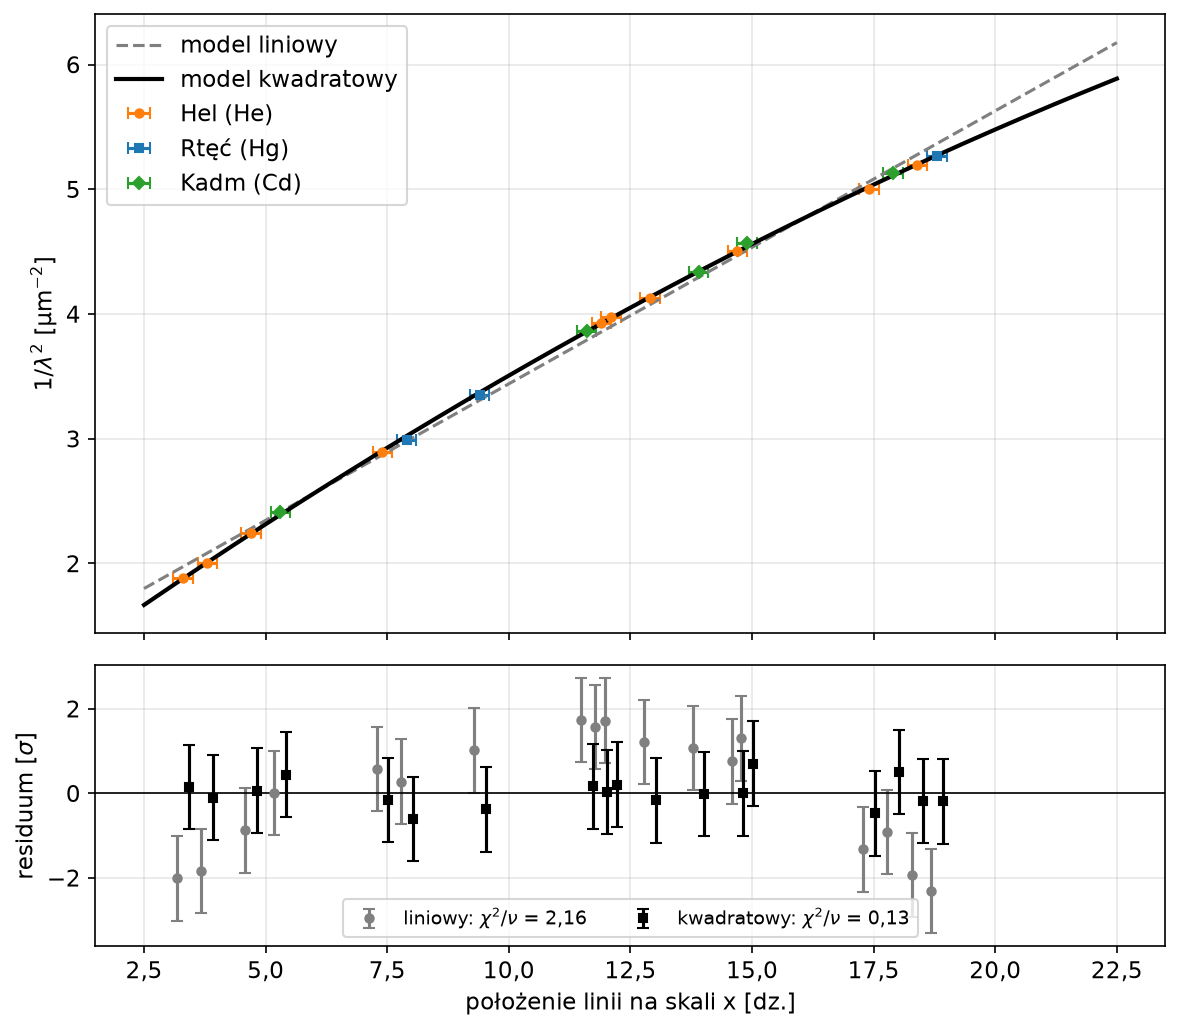

In [6]:
MARK = {'He': ('o', 'tab:orange'), 'Hg': ('s', 'tab:blue'), 'Cd': ('D', 'tab:green')}
xx = np.linspace(2.5, 22.5, 400)
cal_x = cal['x'].values

fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
for sym, (m, c) in MARK.items():
    s = cal['symbol'] == sym
    ax.errorbar(cal_x[s], fits[1]['y'][s], xerr=cal['u_x'][s], fmt=m, ms=4, capsize=3, color=c,
                label=f"{cal.loc[s, 'element'].iloc[0]} ({sym})")
ax.plot(xx, poly(xx, *fits[1]['a']), '--', lw=1.5, color='gray', label='model liniowy')
ax.plot(xx, poly(xx, *fits[2]['a']), '-', lw=2, color='k', label='model kwadratowy')
ax.set_ylabel(r'$1/\lambda^2$ [µm$^{-2}$]')
ax.legend()

for deg, (m, c, off) in {1: ('o', 'gray', -0.12), 2: ('s', 'k', 0.12)}.items():
    f = fits[deg]
    axr.errorbar(cal_x + off, f['res'], yerr=1, fmt=m, ms=4, capsize=3, color=c,
                 label=f"{'liniowy' if deg == 1 else 'kwadratowy'}: " + r'$\chi^2/\nu$ = ' + pl(f['chi2'] / f['ndf'], '.2f'))
axr.axhline(0, color='k', lw=0.8)
axr.set_xlabel('położenie linii na skali x [dz.]')
axr.set_ylabel(r'residuum [$\sigma$]')
axr.legend(fontsize=9, ncol=2, loc='lower center')
fig.tight_layout()
fig.savefig('inverse_square.pdf')
plt.show()

### Krzywa dyspersji $\lambda(x)$

Krzywa kalibracyjna przyrządu: $\lambda(x) = \left(a_1 + a_2 x + a_3 x^2\right)^{-1/2}$ z pasmem $\pm u(\lambda)$
wynikającym z niepewności parametrów (bez niepewności odczytu nowej linii).

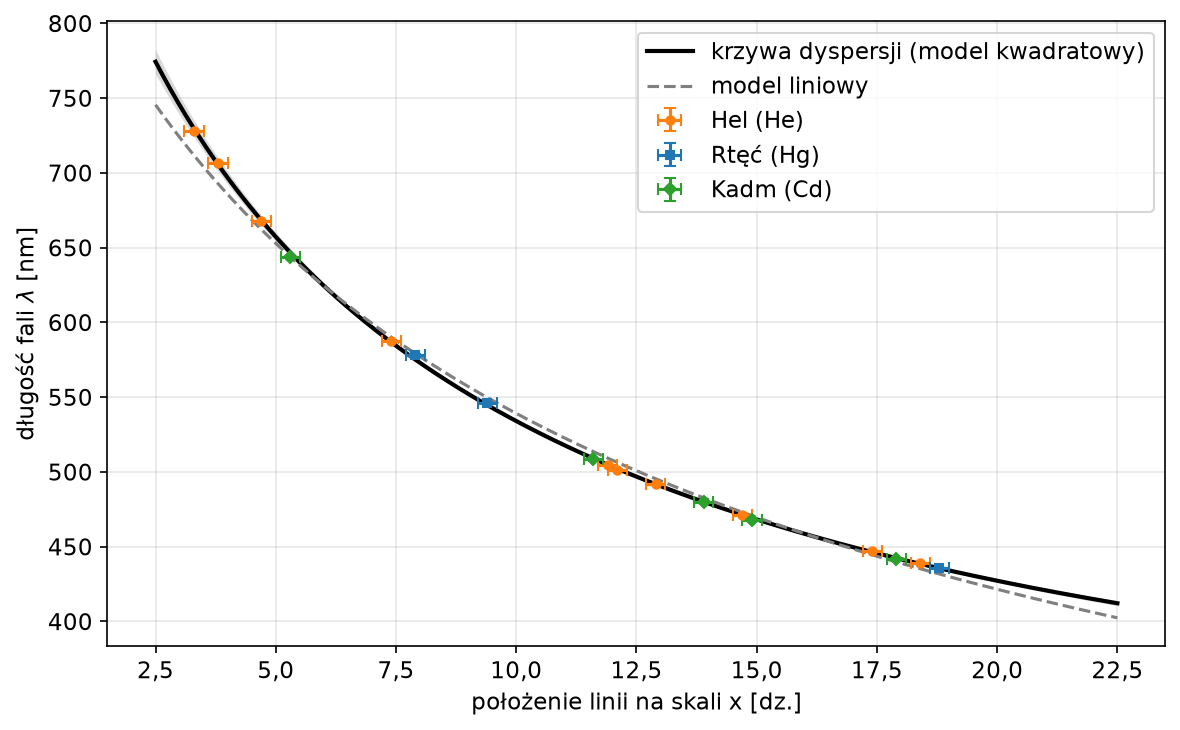

In [7]:
lam_q, _ = predict(f2, xx, 0)
_, u_band = predict(f2, xx, 0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(xx, lam_q - u_band, lam_q + u_band, color='k', alpha=0.15, lw=0)
ax.plot(xx, lam_q, '-', lw=2, color='k', label='krzywa dyspersji (model kwadratowy)')
ax.plot(xx, predict(fits[1], xx, 0)[0], '--', lw=1.5, color='gray', label='model liniowy')
for sym, (m, c) in MARK.items():
    s = cal['symbol'] == sym
    ax.errorbar(cal_x[s], cal['lambda'][s], xerr=cal['u_x'][s], yerr=cal['u_lambda'][s], fmt=m, ms=4, capsize=3,
                color=c, label=f"{cal.loc[s, 'element'].iloc[0]} ({sym})")
ax.set_xlabel('położenie linii na skali x [dz.]')
ax.set_ylabel(r'długość fali $\lambda$ [nm]')
ax.legend()
fig.tight_layout()
fig.savefig('dispersion_curve.pdf')
plt.show()

### Test kalibracji — lampa cynkowa

Długości fal linii Zn z obu modeli, porównanie z tablicą testem $3\sigma$: $|\lambda - \lambda_\text{tab}|/u(\lambda)$.
Niepewność $u(\lambda)$ zawiera kowariancję parametrów i odczyt $u_x$ linii Zn:
$$u^2(y_0) = \mathbf{J}\,C\,\mathbf{J}^T + \left(f'(x_0)\,u_x\right)^2, \qquad
u(\lambda) = \frac{\lambda}{2y_0}\,u(y_0),\qquad \mathbf{J} = (1, x_0, x_0^2).$$

In [8]:
zn = d[(d['symbol'] == 'Zn') & (d['rejected'] == '')].copy()
for deg in (1, 2):
    zn[f'lam{deg}'], zn[f'u_lam{deg}'] = predict(fits[deg], zn['x'].values, zn['u_x'].values)
    zn[f'z{deg}'] = np.abs(zn[f'lam{deg}'] - zn['lambda']) / zn[f'u_lam{deg}']

pd.set_option('display.float_format', '{:.2f}'.format)
print(zn[['line', 'color', 'x', 'lambda', 'lam1', 'u_lam1', 'z1', 'lam2', 'u_lam2', 'z2']].to_string(index=False))

 line          color     x  lambda   lam1  u_lam1   z1   lam2  u_lam2   z2
    1       czerwony  5.50  636.23 638.15    6.06 0.32 640.16    6.98 0.56
    3  morskozielony  9.20     NaN 553.40    3.83  NaN 548.40    3.98  NaN
    4          cyjan 11.00  518.20 522.77    3.21 1.42 517.89    3.23 0.10
    5          cyjan 11.60     NaN 513.64    3.05  NaN 509.06    3.02  NaN
    6 jasny błękitny 13.80  481.05 483.83    2.56 1.09 481.09    2.39 0.02
    7      niebieski 14.50  472.22 475.38    2.44 1.30 473.41    2.23 0.54
    8      niebieski 14.90  468.01 470.75    2.37 1.15 469.24    2.15 0.57


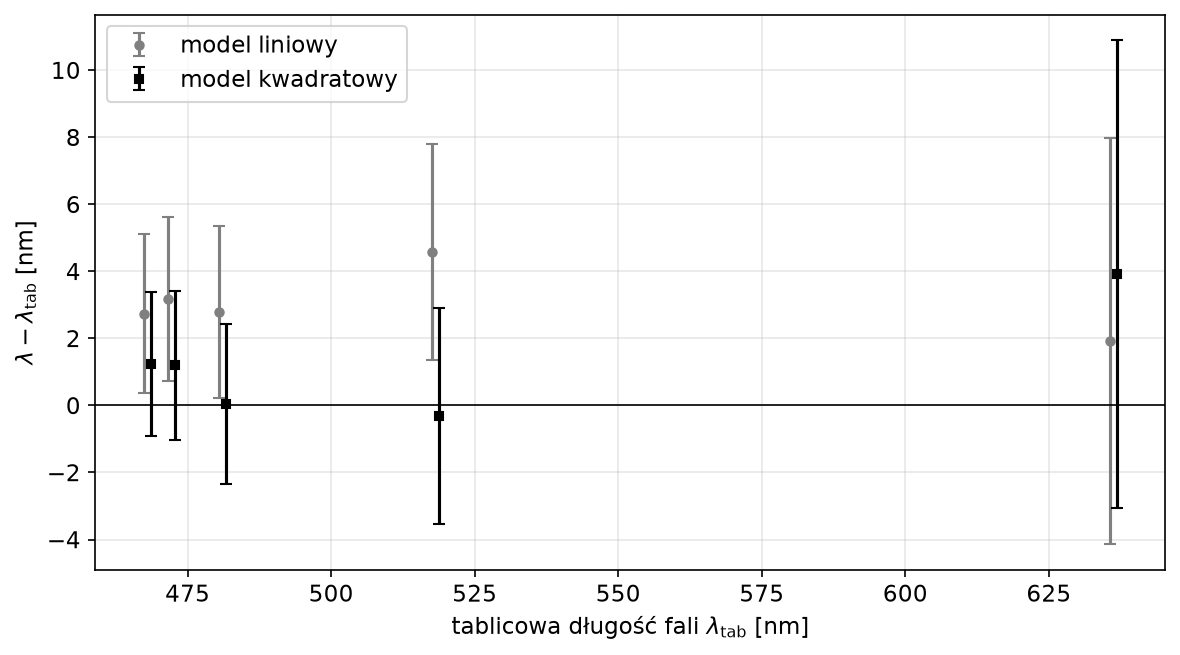

In [9]:
t = zn[zn['role'] == 'test']
fig, ax = plt.subplots(figsize=(8, 4.5))
for deg, (m, c, off) in {1: ('o', 'gray', -0.6), 2: ('s', 'k', 0.6)}.items():
    ax.errorbar(t['lambda'] + off, t[f'lam{deg}'] - t['lambda'], yerr=t[f'u_lam{deg}'], fmt=m, ms=4, capsize=3,
                color=c, label='model liniowy' if deg == 1 else 'model kwadratowy')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel(r'tablicowa długość fali $\lambda_\mathrm{tab}$ [nm]')
ax.set_ylabel(r'$\lambda - \lambda_\mathrm{tab}$ [nm]')
ax.legend()
fig.tight_layout()
fig.savefig('zinc_test.pdf')
plt.show()

### Linie Zn bez odpowiednika w tablicy Zn I

Dla linii lampy cynkowej, którym nie przypisano linii Zn, szukano najbliższej linii w tablicy wzorców innych pierwiastków.

In [10]:
for r in zn[zn['role'] == ''].itertuples():
    k = (ref['lambda'] - r.lam2).abs().idxmin()
    near = ref.loc[k]
    print(f"Zn {r.line} ({r.color}, x = {r.x}): λ = {r.lam2:.1f} ± {r.u_lam2:.1f} nm; "
          f"najbliższa: {near['spectrum']} {near['lambda']:.2f} nm "
          f"({abs(r.lam2 - near['lambda']) / r.u_lam2:.1f}σ)")

Zn 3 (morskozielony, x = 9.2): λ = 548.4 ± 4.0 nm; najbliższa: Hg I 546.08 nm (0.6σ)
Zn 5 (cyjan, x = 11.6): λ = 509.1 ± 3.0 nm; najbliższa: Cd I 508.58 nm (0.2σ)


### Skala w nanometrach — wszystkie widma

Każde położenie na skali przeliczono modelem kwadratowym na długość fali (z niepewnością jak dla linii Zn).

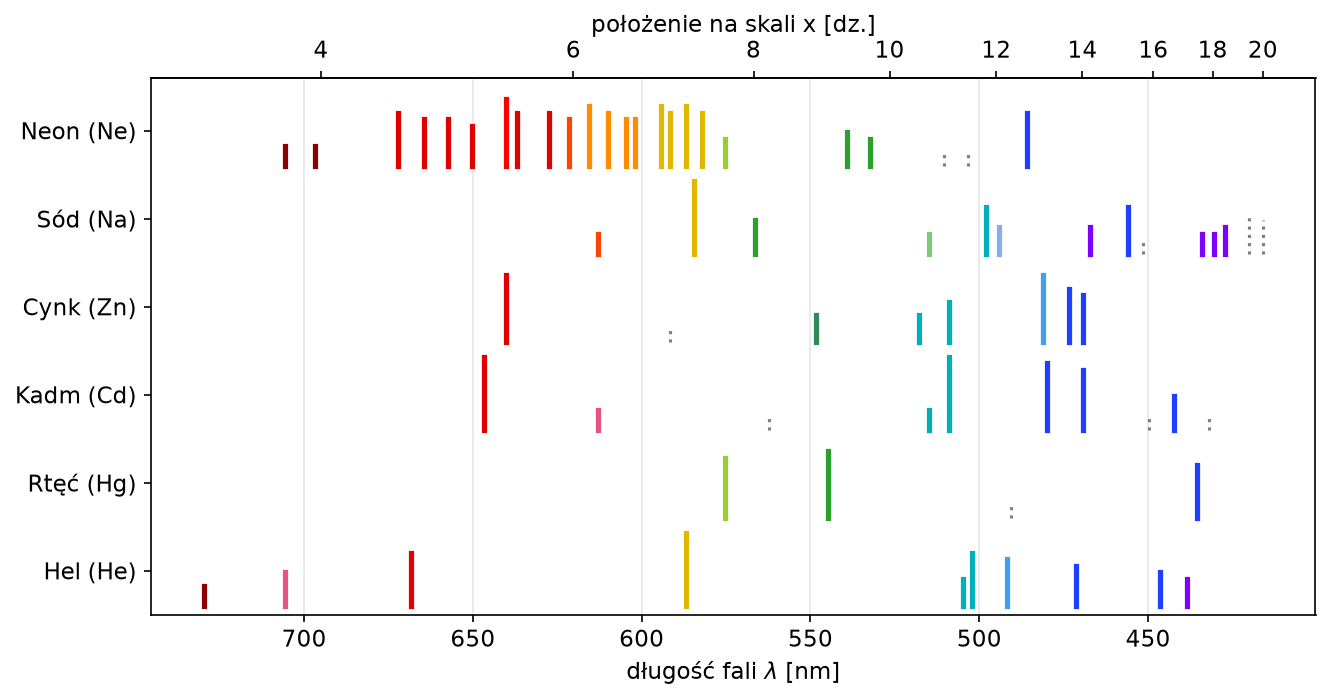

In [11]:
d['lambda_cal'], d['u_lambda_cal'] = predict(f2, d['x'].values, d['u_x'].values)

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_spectra(ax, d['lambda_cal'], d)
ax.set_xlabel(r'długość fali $\lambda$ [nm]')
ax.invert_xaxis()   # ten sam kierunek co skala spektroskopu (czerwień po lewej)
secax = ax.secondary_xaxis('top', functions=(lambda l: np.interp(l, lam_q[::-1], xx[::-1]),
                                             lambda x: np.interp(x, xx, lam_q)))
secax.set_xticks(np.arange(4, 21, 2))   # skala nieliniowa w λ — gęstsze podziałki nachodziłyby na siebie
secax.set_xlabel('położenie na skali x [dz.]')
fig.tight_layout()
fig.savefig('spectra_calibrated.pdf')
plt.show()

### Porównanie z NIST — neon, sód i nieprzypisane linie kadmu

`nist_candidates.csv` — linie kandydujące z NIST ASD (powietrze):
- Ne I o względnej intensywności $I_\text{NIST} \geq 1000$, $\lambda \geq 400$ nm,
- dublety Na I (średnia składowych, $u_\lambda$ = połowa odstępu — spektroskop ich nie rozdziela; NIST nie podaje dla nich
  porównywalnych intensywności),
- wszystkie linie Cd I w zakresie 390–760 nm (do identyfikacji słabych linii Cd 2 i Cd 4; linie Cd użyte w kalibracji
  są wyłączone).

Przypisanie (programowanie dynamiczne): każda linia NIST użyta co najwyżej raz, kolejność długości fal zachowana
(linie na skali nie mogą się „przeplatać”), minimalizowany koszt
$$K = \sum_\text{przypisane}\left[z_i^2 - \beta\, b_i \log_{10}\frac{I_j}{I_0}\right] + 3^2\cdot N_\text{nieprzypisane},
\qquad z_i = \frac{|\lambda_i - \lambda_j|}{\sqrt{u^2(\lambda_i) + u_{\lambda,j}^2}} \leq 3,$$
gdzie $b_i$ — zanotowana jasność linii / 10, $I_j$ — intensywność linii NIST, $I_0$ — najmniejsza intensywność
wśród kandydatów danego pierwiastka. Drugi człon nagradza dopasowanie **jasnej** linii obserwowanej do **silnej**
linii tablicowej — samo $\sum z^2$ nie zna jasności i przy gęstym widmie Ne daje fizycznie nienaturalne przypisania
(np. najjaśniejsza linia Ne 7 dostawała słabszą 638,30 nm zamiast 640,22 nm, a silna 585,25 nm zostawała nieużyta).
Przyjęto $\beta = 2$; kolumna `stable` mówi, czy przypisanie jest takie samo dla każdego $\beta \in \{1, 2, 3, 4\}$.

Kolumna `n_2sigma` — liczba kandydatów w odległości $\leq 2\sigma$; $> 1$ oznacza, że identyfikacja nie jest jednoznaczna.

In [12]:
nist = pd.read_csv('nist_candidates.csv')
BETA, BETAS = 2.0, [1.0, 2.0, 3.0, 4.0]

def assign(lam, u, b, cand_lam, cand_u, cand_I, beta, z_max=3.0):
    '''Monotoniczne przypisanie 1:1 linii zmierzonych (λ malejąco) do kandydatów (λ malejąco), min. koszt K.'''
    n, m = len(lam), len(cand_lam)
    z = np.abs(lam[:, None] - cand_lam[None, :]) / np.sqrt(u[:, None]**2 + cand_u[None, :]**2)
    gain = beta * b[:, None] * np.log10(cand_I[None, :] / cand_I.min())
    cost = np.where(z <= z_max, z**2 - gain, np.inf)
    D = np.zeros((n + 1, m + 1))
    D[1:, 0] = z_max**2 * np.arange(1, n + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = min(D[i, j - 1], D[i - 1, j] + z_max**2, D[i - 1, j - 1] + cost[i - 1, j - 1])
    match, i, j = [-1] * n, n, m
    while i > 0:
        if j > 0 and D[i, j] == D[i, j - 1]:
            j -= 1
        elif j > 0 and np.isfinite(cost[i - 1, j - 1]) and np.isclose(D[i, j], D[i - 1, j - 1] + cost[i - 1, j - 1]):
            match[i - 1] = j - 1; i -= 1; j -= 1
        else:
            i -= 1
    return np.array(match), z

d['u_lambda'] = d['u_lambda'].fillna(0)
d['spectrum'] = d['spectrum'].fillna('')
d['n_2sigma'] = np.nan
d['stable'] = ''
for sym in ['Ne', 'Na', 'Cd']:
    sel = d.index[(d['symbol'] == sym) & (d['rejected'] == '') & (d['role'] == '')]
    sel = sel[np.argsort(d.loc[sel, 'x'].values)]
    c = nist[nist['symbol'] == sym]
    cal_lams = d.loc[(d['role'] == 'calibration') & (d['symbol'] == sym), 'lambda'].values   # linie tego pierwiastka już użyte w kalibracji
    c = c[~(np.abs(c['lambda'].values[:, None] - cal_lams[None, :]) < 1e-3).any(axis=1)]
    c = c.sort_values('lambda', ascending=False).reset_index(drop=True)
    I = c['nist_intensity'].fillna(c['nist_intensity'].min()).fillna(1).values.astype(float)
    args = (d.loc[sel, 'lambda_cal'].values, d.loc[sel, 'u_lambda_cal'].values, d.loc[sel, 'intensity'].values / 10,
            c['lambda'].values, c['u_lambda'].values, I)
    match, z = assign(*args, BETA)
    others = [assign(*args, b)[0] for b in BETAS]
    d.loc[sel, 'n_2sigma'] = (z <= 2).sum(axis=1)
    d.loc[sel, 'stable'] = np.where(np.all([o == match for o in others], axis=0), 'tak', 'nie')
    for k, j in zip(sel, match):
        if j >= 0:
            d.loc[k, ['lambda', 'u_lambda', 'spectrum', 'role']] = [c.loc[j, 'lambda'], c.loc[j, 'u_lambda'],
                                                                     c.loc[j, 'spectrum'], 'comparison']
            d.loc[k, 'nist_intensity'] = c.loc[j, 'nist_intensity']

cmp_ = d[d['role'].isin(['test', 'comparison'])].copy()
cmp_['diff'] = cmp_['lambda_cal'] - cmp_['lambda']
cmp_['z'] = np.abs(cmp_['diff']) / np.sqrt(cmp_['u_lambda_cal']**2 + cmp_['u_lambda']**2)
print(cmp_[['symbol', 'line', 'intensity', 'x', 'lambda_cal', 'u_lambda_cal', 'lambda', 'nist_intensity', 'diff', 'z',
            'n_2sigma', 'stable']].to_string(index=False))

for sym in ['Zn', 'Na', 'Ne', 'Cd']:
    s = cmp_[cmp_['symbol'] == sym]
    print(f"{sym}: przypisano {len(s)}, zgodnych w 3σ: {(s['z'] <= 3).sum()}, "
          f"średnia różnica {s['diff'].mean():+.2f} nm, max z = {s['z'].max():.2f}")
print('nieprzypisane:', d.loc[(d['role'] == '') & (d['rejected'] == ''), ['symbol', 'line']].apply(tuple, axis=1).tolist())

symbol  line  intensity     x  lambda_cal  u_lambda_cal  lambda  nist_intensity  diff    z  n_2sigma stable
    Ne     1          2  3.80      705.61         10.21  703.24        85000.00  2.37 0.23      7.00    tak
    Ne     2          2  4.00      696.71          9.71  692.95       100000.00  3.77 0.39      5.00    tak
    Ne     3          7  4.60      672.12          8.43  667.83         5000.00  4.29 0.51      5.00    tak
    Ne     4          6  4.80      664.55          8.06  665.21         1500.00 -0.66 0.08      7.00    tak
    Ne     5          6  5.00      657.26          7.73  659.90        10000.00 -2.64 0.34      9.00    tak
    Ne     6          5  5.20      650.23          7.41  650.65        15000.00 -0.42 0.06     11.00    tak
    Ne     7          9  5.50      640.16          6.98  640.22        20000.00 -0.07 0.01     17.00    tak
    Ne     8          7  5.60      636.92          6.85  638.30        10000.00 -1.38 0.20     17.00    tak
    Ne     9          7  5.9

### Silne linie Ne I nieprzypisane żadnej obserwowanej linii

Linie Ne I o $I_\text{NIST} \geq 10\,000$ w zakresie obserwowanego widma neonu, którym nie przypisano żadnej linii.

In [13]:
ne_obs = d[(d['symbol'] == 'Ne') & (d['rejected'] == '')]
lo, hi = ne_obs['lambda_cal'].min(), ne_obs['lambda_cal'].max()
used = d.loc[(d['symbol'] == 'Ne') & (d['role'] == 'comparison'), 'lambda'].values
strong = nist[(nist['symbol'] == 'Ne') & (nist['nist_intensity'] >= 10000) & nist['lambda'].between(lo, hi)]
print(strong[~np.isin(strong['lambda'], used)][['lambda', 'nist_intensity']].to_string(index=False))

 lambda  nist_intensity
 488.49        10000.00
 495.70        10000.00
 534.11        10000.00
 633.44        10000.00
 702.40        34000.00


### Koincydencje położeń między lampami

Dla linii nieprzypisanych do widma własnego pierwiastka lub podejrzanych o domieszkę: linie innych źródeł
w odległości $|\Delta x| \leq u_x$.

In [14]:
for sym, ln in [('Zn', 3), ('Zn', 5), ('Cd', 2), ('Cd', 4), ('Na', 6)]:
    r = d[(d['symbol'] == sym) & (d['line'] == ln)].iloc[0]
    near = d[(d['symbol'] != sym) & ((d['x'] - r['x']).abs() <= r['u_x'] + 1e-9)]
    print(f"{sym} {ln} (x = {r['x']}, {r['color']}): " +
          '; '.join(f"{q.symbol} {q.line} (x = {q.x}, jasność {q.intensity}, {q.color})" for q in near.itertuples()))

Zn 3 (x = 9.2, morskozielony): Hg 2 (x = 9.4, jasność 9, zielony)
Zn 5 (x = 11.6, cyjan): Ne 22 (x = 11.5, jasność 1, szarozielony (bardzo słaby)); Cd 5 (x = 11.6, jasność 10, cyjan)
Cd 2 (x = 6.4, różowoczerwony (słaby)): Ne 11 (x = 6.3, jasność 8, pomarańczowy); Ne 12 (x = 6.5, jasność 7, pomarańczowy); Na 1 (x = 6.4, jasność 2, pomarańczowoczerwony (słaby))
Cd 4 (x = 11.2, cyjan (słaby)): Na 4 (x = 11.2, jasność 2, bladozielony); Zn 4 (x = 11.0, jasność 3, cyjan)
Na 6 (x = 12.7, bladoniebieski): He 7 (x = 12.9, jasność 6, błękitny)


### Test obciążenia kalibracji

Test $3\sigma$ dla pojedynczych linii ma przy zawyżonym $u_x$ małą moc (przechodzi nawet model liniowy). Czulszym
sprawdzianem jest **średnia różnica** $\overline{\lambda - \lambda_\text{NIST}}$ dla niezależnych linii: Zn I (test) oraz
linii Na z jednoznaczną identyfikacją ($n_{2\sigma} = 1$). Niepewność średniej liczona z pełną macierzą kowariancji —
składowa od parametrów krzywej jest wspólna dla wszystkich linii (skorelowana), składowa od $u_x$ — niezależna.

In [15]:
def bias(fit, x, lam_tab, u_tab):
    J = np.stack([x**i for i in range(len(fit['a']))], axis=1)
    y = J @ fit['a']
    lam = 1e3 / np.sqrt(y)
    g_ = (lam / (2 * y))[:, None] * J                      # dλ/da_i
    V = g_ @ fit['C'] @ g_.T + np.diag((lam / (2 * y) * dpoly(x, fit['a']) * 0.2)**2 + u_tab**2)
    w = np.full(len(x), 1 / len(x))
    m, um = w @ (lam - lam_tab), np.sqrt(w @ V @ w)
    return m, um, np.sqrt(w @ (g_ @ fit['C'] @ g_.T) @ w)

na_u = cmp_[(cmp_['symbol'] == 'Na') & (cmp_['n_2sigma'] == 1)]
zn_t = cmp_[cmp_['symbol'] == 'Zn']
sets = {'Zn (5 linii)': zn_t, f'Na jednoznaczne ({len(na_u)} linii)': na_u, 'Zn + Na': pd.concat([zn_t, na_u])}
for name, s in sets.items():
    for deg in (1, 2):
        m, um, up = bias(fits[deg], s['x'].values, s['lambda'].values, s['u_lambda'].values)
        print(f"{name:24s} model {'liniowy   ' if deg == 1 else 'kwadratowy'}: średnia λ − λ_NIST = {m:+.2f} ± {um:.2f} nm "
              f"({abs(m) / um:.1f}σ; w tym od parametrów ±{up:.2f} nm)")

Zn (5 linii)             model liniowy   : średnia λ − λ_NIST = +3.03 ± 1.72 nm (1.8σ; w tym od parametrów ±0.76 nm)
Zn (5 linii)             model kwadratowy: średnia λ − λ_NIST = +1.22 ± 1.82 nm (0.7σ; w tym od parametrów ±0.83 nm)
Na jednoznaczne (7 linii) model liniowy   : średnia λ − λ_NIST = +1.56 ± 1.59 nm (1.0σ; w tym od parametrów ±0.84 nm)
Na jednoznaczne (7 linii) model kwadratowy: średnia λ − λ_NIST = -1.14 ± 1.69 nm (0.7σ; w tym od parametrów ±0.96 nm)
Zn + Na                  model liniowy   : średnia λ − λ_NIST = +2.17 ± 1.29 nm (1.7σ; w tym od parametrów ±0.81 nm)
Zn + Na                  model kwadratowy: średnia λ − λ_NIST = -0.16 ± 1.39 nm (0.1σ; w tym od parametrów ±0.90 nm)


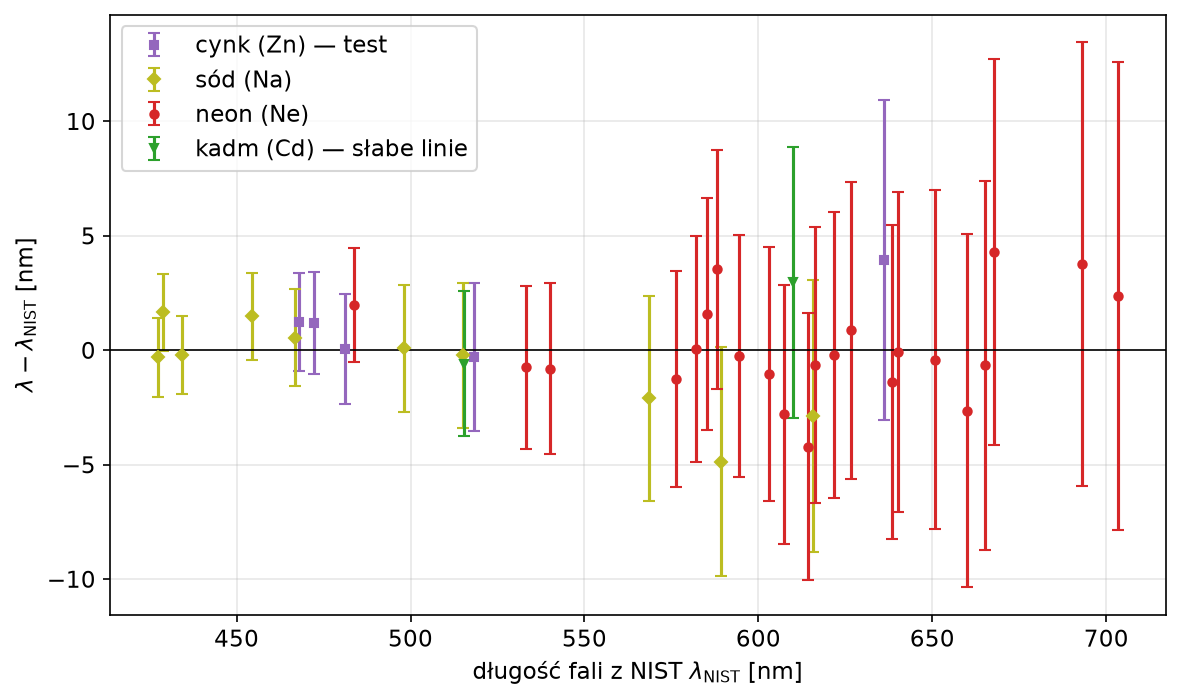

In [16]:
CMP = {'Zn': ('s', 'tab:purple', 'cynk (Zn) — test'), 'Na': ('D', 'tab:olive', 'sód (Na)'),
       'Ne': ('o', 'tab:red', 'neon (Ne)'), 'Cd': ('v', 'tab:green', 'kadm (Cd) — słabe linie')}
fig, ax = plt.subplots(figsize=(8, 4.8))
for sym, (m, c, lab) in CMP.items():
    s = cmp_[cmp_['symbol'] == sym]
    ax.errorbar(s['lambda'], s['diff'], yerr=np.sqrt(s['u_lambda_cal']**2 + s['u_lambda']**2),
                fmt=m, ms=4, capsize=3, color=c, label=lab)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel(r'długość fali z NIST $\lambda_\mathrm{NIST}$ [nm]')
ax.set_ylabel(r'$\lambda - \lambda_\mathrm{NIST}$ [nm]')
ax.legend()
fig.tight_layout()
fig.savefig('nist_comparison.pdf')
plt.show()

### Zapis wyników

`calibrated_lines.csv` — wszystkie linie: położenie, długość fali z kalibracji, przypisana linia tablicowa
(`lambda`, `spectrum`) i rola (`calibration` / `test` / `comparison`).

In [17]:
d.to_csv('calibrated_lines.csv', index=False, float_format='%.2f',
         columns=['element', 'symbol', 'line', 'color', 'x', 'u_x', 'intensity', 'rejected', 'role', 'stable',
                  'lambda_cal', 'u_lambda_cal', 'lambda', 'u_lambda', 'spectrum', 'nist_intensity', 'n_2sigma'])